# Notebook 09 — Modelo Final de Machine Learning y Simulación de La Liga

**Proyecto Integrador: Analítica y Predicción de Resultados en La Liga**

En este notebook cerramos la parte de modelado del proyecto. La pregunta que queremos responder es:

> **¿Podemos predecir si el equipo local gana, empata o pierde usando solo la información que existía antes del partido? Y con esas probabilidades, ¿cómo podría terminar la temporada en curso?**

Trabajamos con la base histórica de **FBref** (temporadas 2006/07 a 2026/27) que limpiamos en el notebook `08_EDA_limpieza`.

### Contenido
1. Librerías
2. Carga de datos
3. Distribución de las variables
4. Ingeniería de variables sin fuga de información
5. Variable objetivo y división temporal
6. Comparación de modelos base
7. Pipeline final: modelos calibrados
8. Proyección de la temporada 2026/27
9. Simulación Monte Carlo
10. Visualización de resultados
11. Conclusiones finales

## 1. Librerías

Usamos `pandas` y `numpy` para manipular los datos, `matplotlib` y `seaborn` para graficar, y `scikit-learn` y `xgboost` para los modelos y sus métricas.

In [ ]:
# Importar librerias
import pandas as pd             # Para cargar los CSVs, hacer cruces relacionales y manipular la matriz
import numpy as np              # Para operaciones vectoriales de alto rendimiento
import os                       # Para manejar las rutas relativas de los archivos en tu repositorio
import seaborn as sns                  # Para hacer gráficos estadísticos de alta calidad
import matplotlib.pyplot as plt        # Para hacer gráficos estadísticos de alta calidad
from sklearn.preprocessing import LabelEncoder        # Para transformar nuestro Target (0, 1, 3 pts) a un formato secuencial (0, 1, 2)
from sklearn.preprocessing import StandardScaler      # Para escalar todas las estadísticas; evita que los minutos (miles) aplasten a los goles (unidades)

from sklearn.metrics import accuracy_score            # Calcula el porcentaje base de acierto del modelo
from sklearn.metrics import classification_report     # Genera el resumen de Precision, Recall y F1-Score
from sklearn.metrics import f1_score                  # Balance entre precision y recall por clase
from sklearn.metrics import log_loss                  # Penaliza probabilidades seguras que resultan equivocadas
from sklearn.metrics import brier_score_loss          # Error cuadratico entre la probabilidad y lo que paso
from sklearn.calibration import CalibratedClassifierCV # Suaviza las probabilidades del modelo
from sklearn.linear_model import LogisticRegression   # El baseline estadístico; traza líneas de probabilidad.
from sklearn.tree import DecisionTreeClassifier       # Algoritmo puro de reglas "Si / Entonces".
from sklearn.ensemble import RandomForestClassifier   # Ensamble que promedia la opinión de cientos de árboles de decisión.
from sklearn.naive_bayes import GaussianNB            # Algoritmo basado puramente en probabilidades (Teorema de Bayes).
from xgboost import XGBClassifier                     # Boosting: árboles que se entrenan en secuencia corrigiendo los errores del anterior.

## 2. Carga de datos

Cargamos las cuatro tablas históricas limpias de FBref:

| Tabla | Qué contiene |
| --- | --- |
| `partidos` | Un renglón por partido: fecha, local, visitante, goles y puntos de cada lado. |
| `equipos` | Estadísticas por equipo y temporada (edad, posesión, goles, asistencias, tarjetas...). |
| `tabla general` | Clasificación por temporada (PJ, G, E, P, GF, GC, puntos). |
| `jugadores` | Estadísticas individuales por jugador y temporada. |

La tabla de **partidos** es la base del modelo; la **tabla general** la usamos al final para conocer los puntos actuales de cada equipo en 2026/27.

In [ ]:
# Configuración de Pandas para mostrar todas las columnas
pd.set_option('display.max_columns', None)


# Ruta de los archivos limpios
ruta_clean = os.path.abspath(os.path.join(os.getcwd(), "..", "data", "fbref", "processed", "clean"))

# Cargamos las cuatro tablas históricas limpias (salida del notebook 08)
df_partidos = pd.read_csv(os.path.join(ruta_clean, "partidos_historico_limpio.csv"))
df_equipos = pd.read_csv(os.path.join(ruta_clean, "equipos_historico_limpio.csv"))
df_tabla = pd.read_csv(os.path.join(ruta_clean, "tabla_general_historico_limpio.csv"))
df_jugadores = pd.read_csv(os.path.join(ruta_clean, "jugadores_historico_limpio.csv"), low_memory=False)

print(f"Partidos: {df_partidos.shape[0]} filas | Equipos: {df_equipos.shape[0]} filas")

Partidos: 7720 filas | Equipos: 420 filas


## 3. Distribución de las variables

Antes de modelar revisamos cómo se distribuyen las variables numéricas de cada tabla. Esto nos ayuda a detectar valores raros y a entender la escala de cada variable.

Lo más importante para el modelo:
- Los **goles** por partido son conteos pequeños y discretos (casi siempre entre 0 y 4), con sesgo a la derecha.
- Las escalas son muy distintas entre variables (por ejemplo, **minutos** en miles contra **goles** en unidades). Por eso más adelante **estandarizamos** las variables con `StandardScaler`.

 Análisis de Distribución de las Variables

Partidos: 4 variables numéricas
Goles_Local, Goles_Visita, Puntos_Local, Puntos_Visita

Equipos: 19 variables numéricas
Age, Poss, MP, Starts, Min, 90s, Gls, Ast, G+A, G-PK, PK, PKatt, CrdY, CrdR, Gls_per90, Ast_per90, G+A_per90, G-PK_per90, G+A-PK_per90

Tabla general: 9 variables numéricas
MP, W, D, L, GF, GA, GD, Pts, Pts/MP

Jugadores: 18 variables numéricas
Age, MP, Starts, Min, 90s, Gls, Ast, G+A, G-PK, PK, PKatt, CrdY, CrdR, Gls.1, Ast.1, G+A.1, G-PK.1, G+A-PK


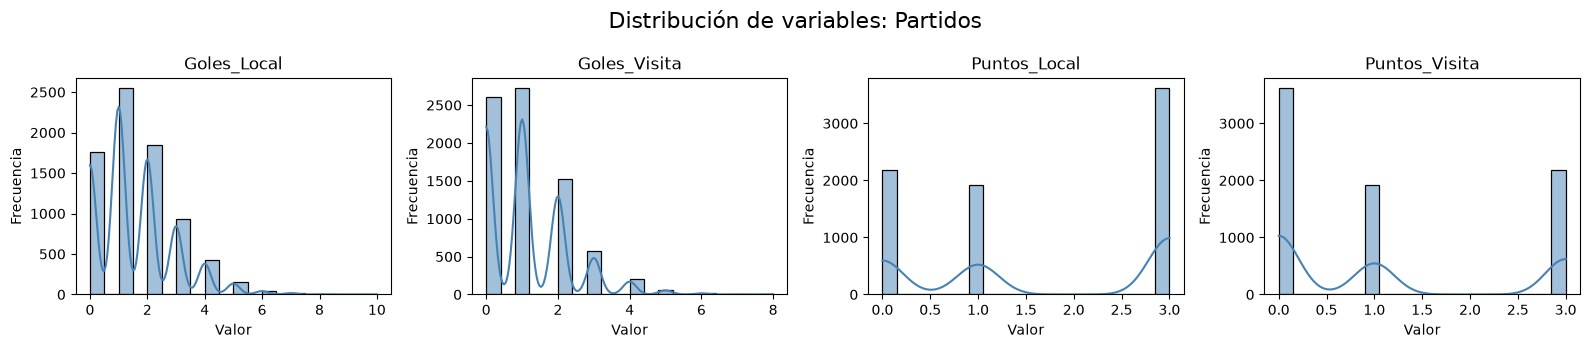

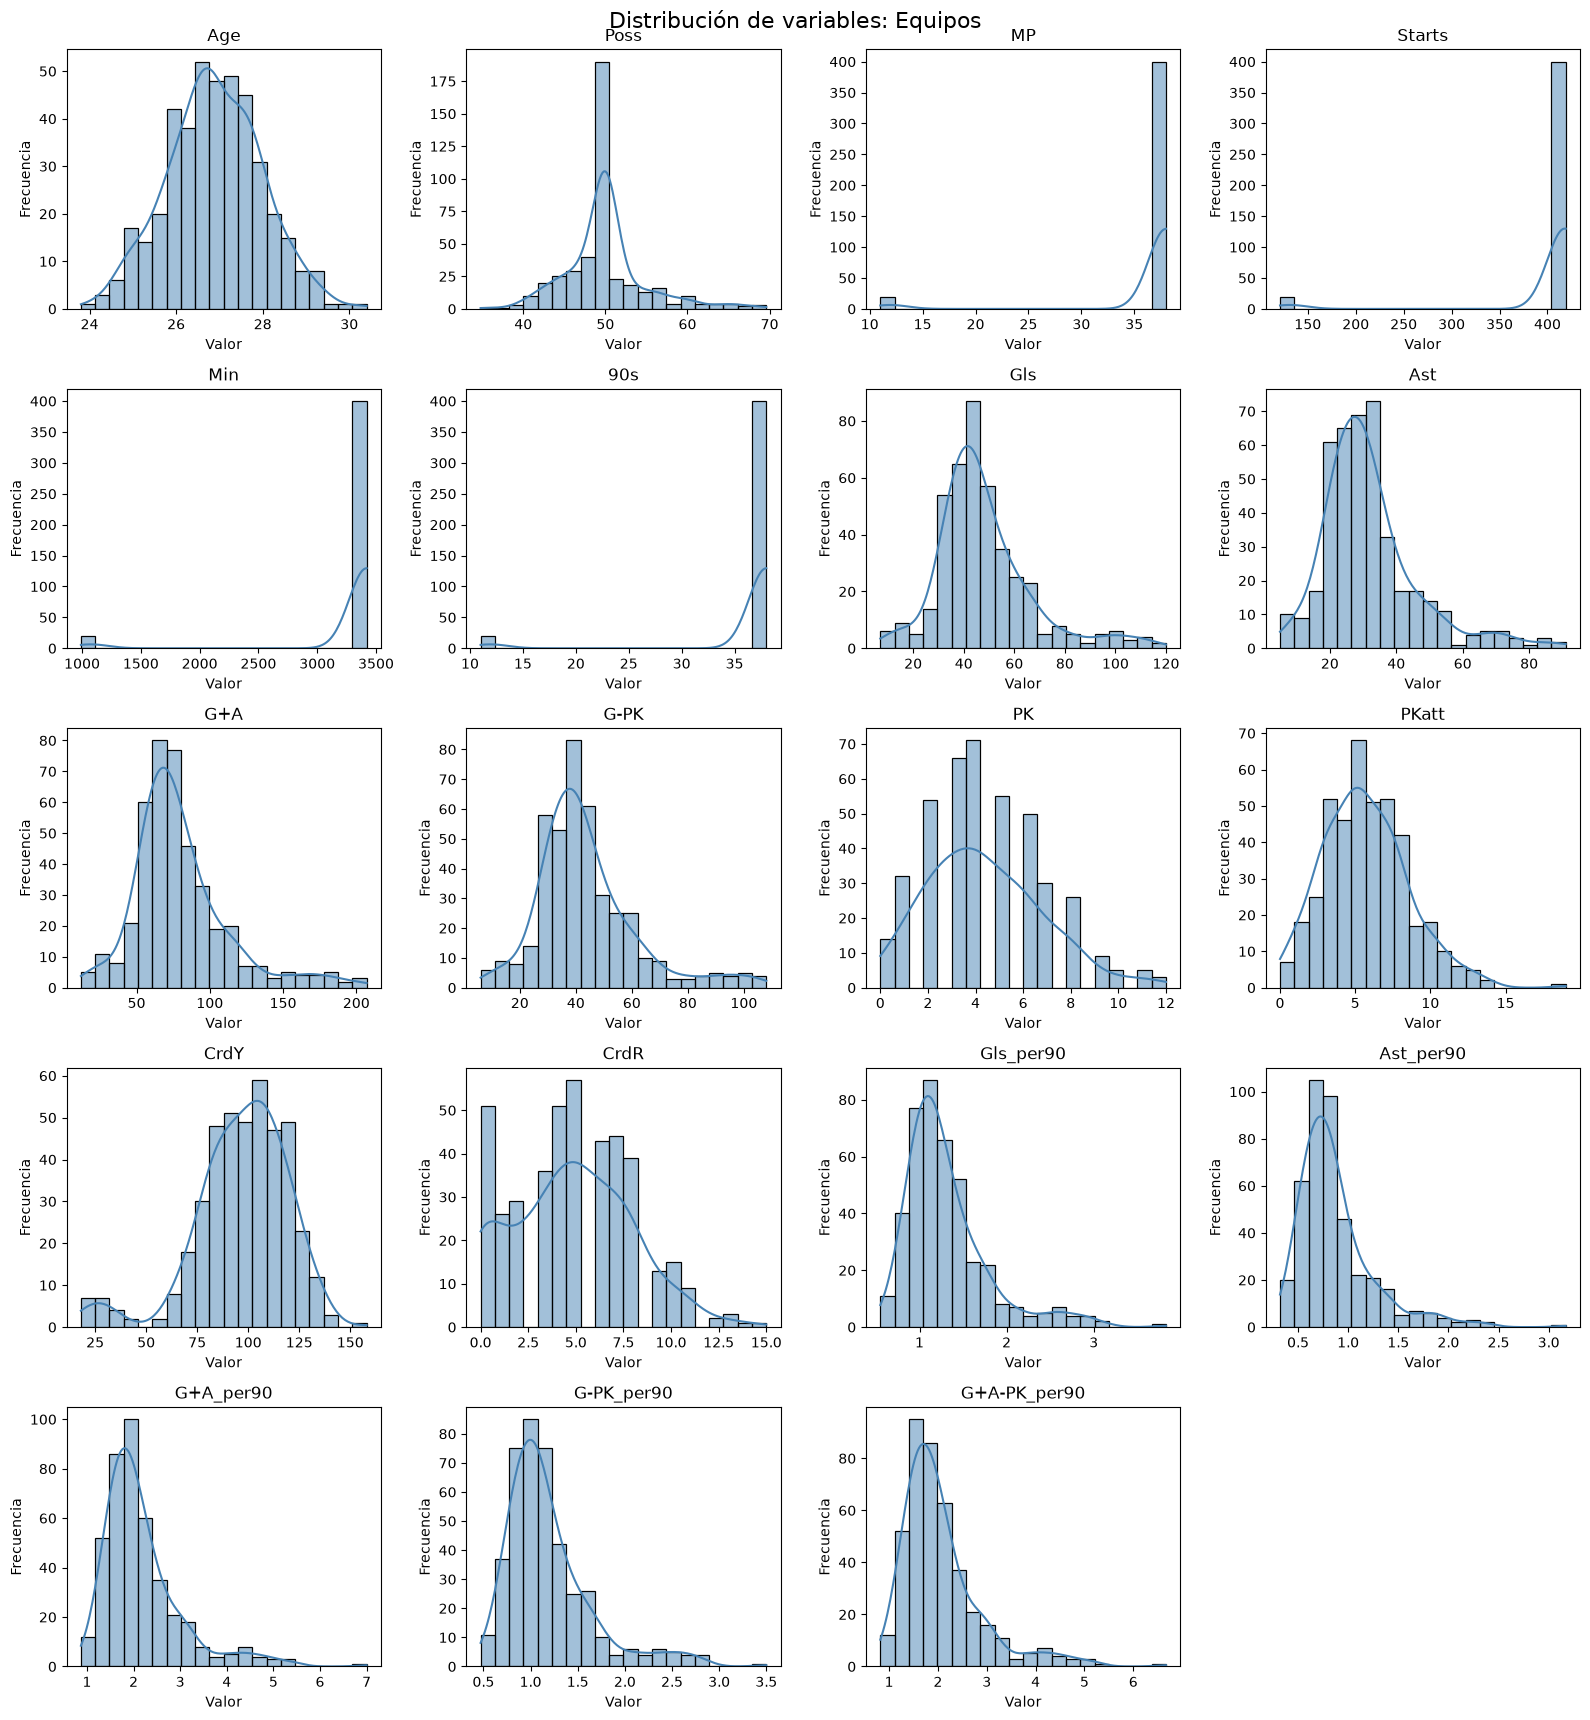

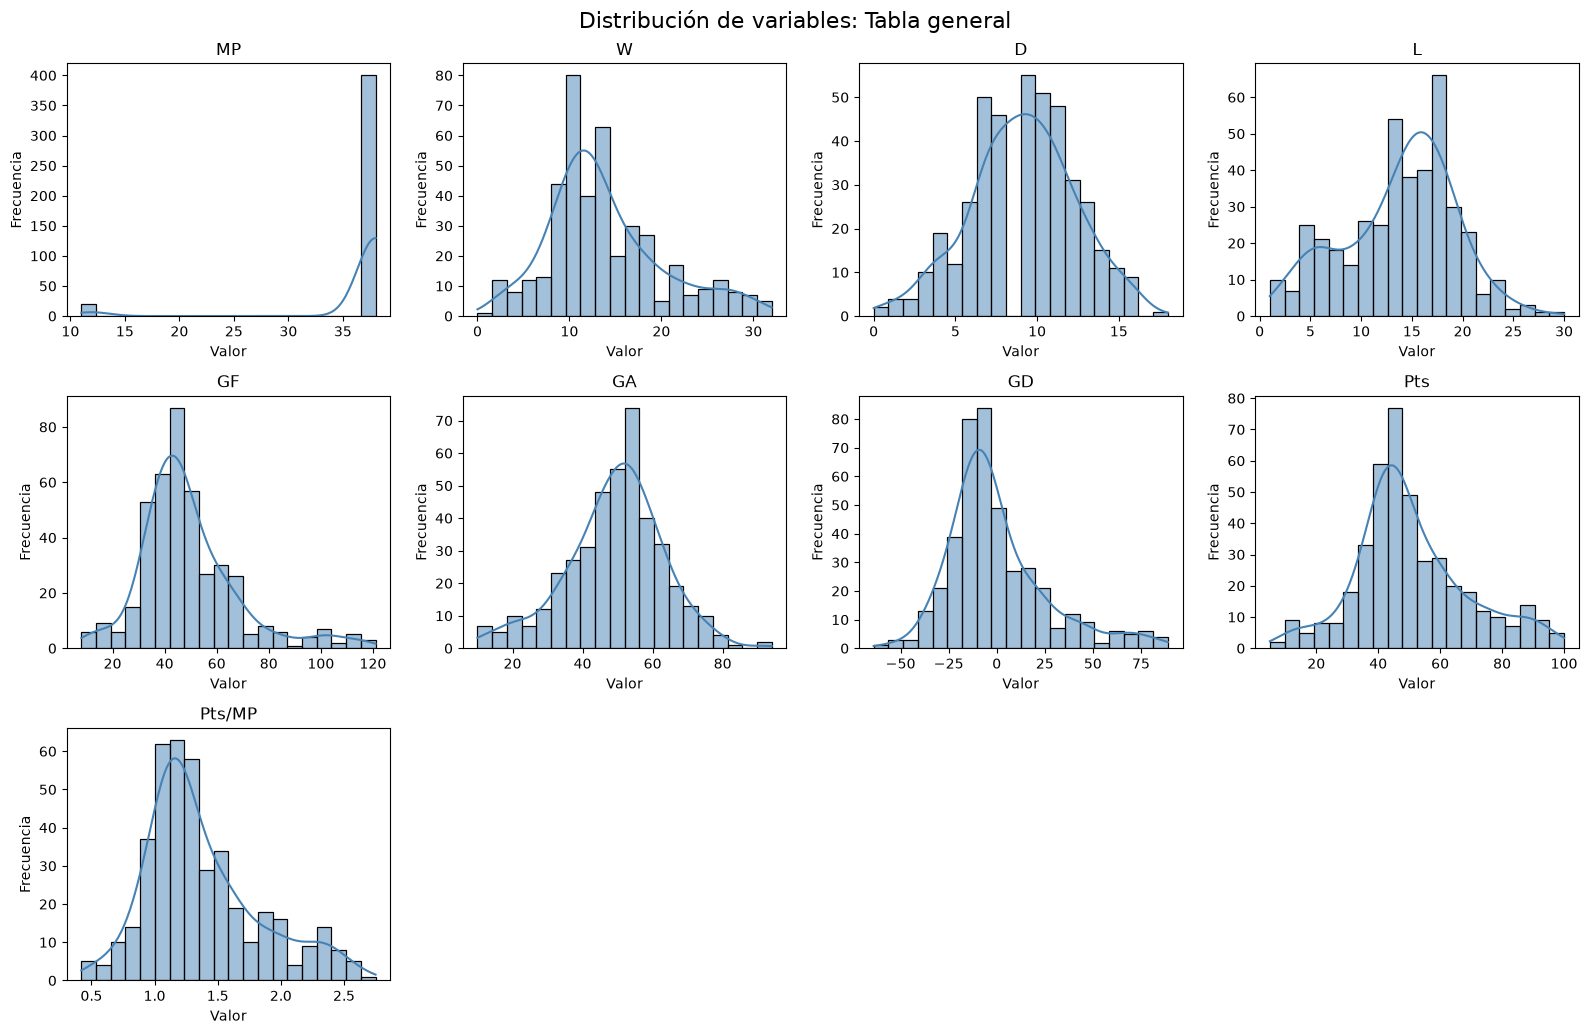

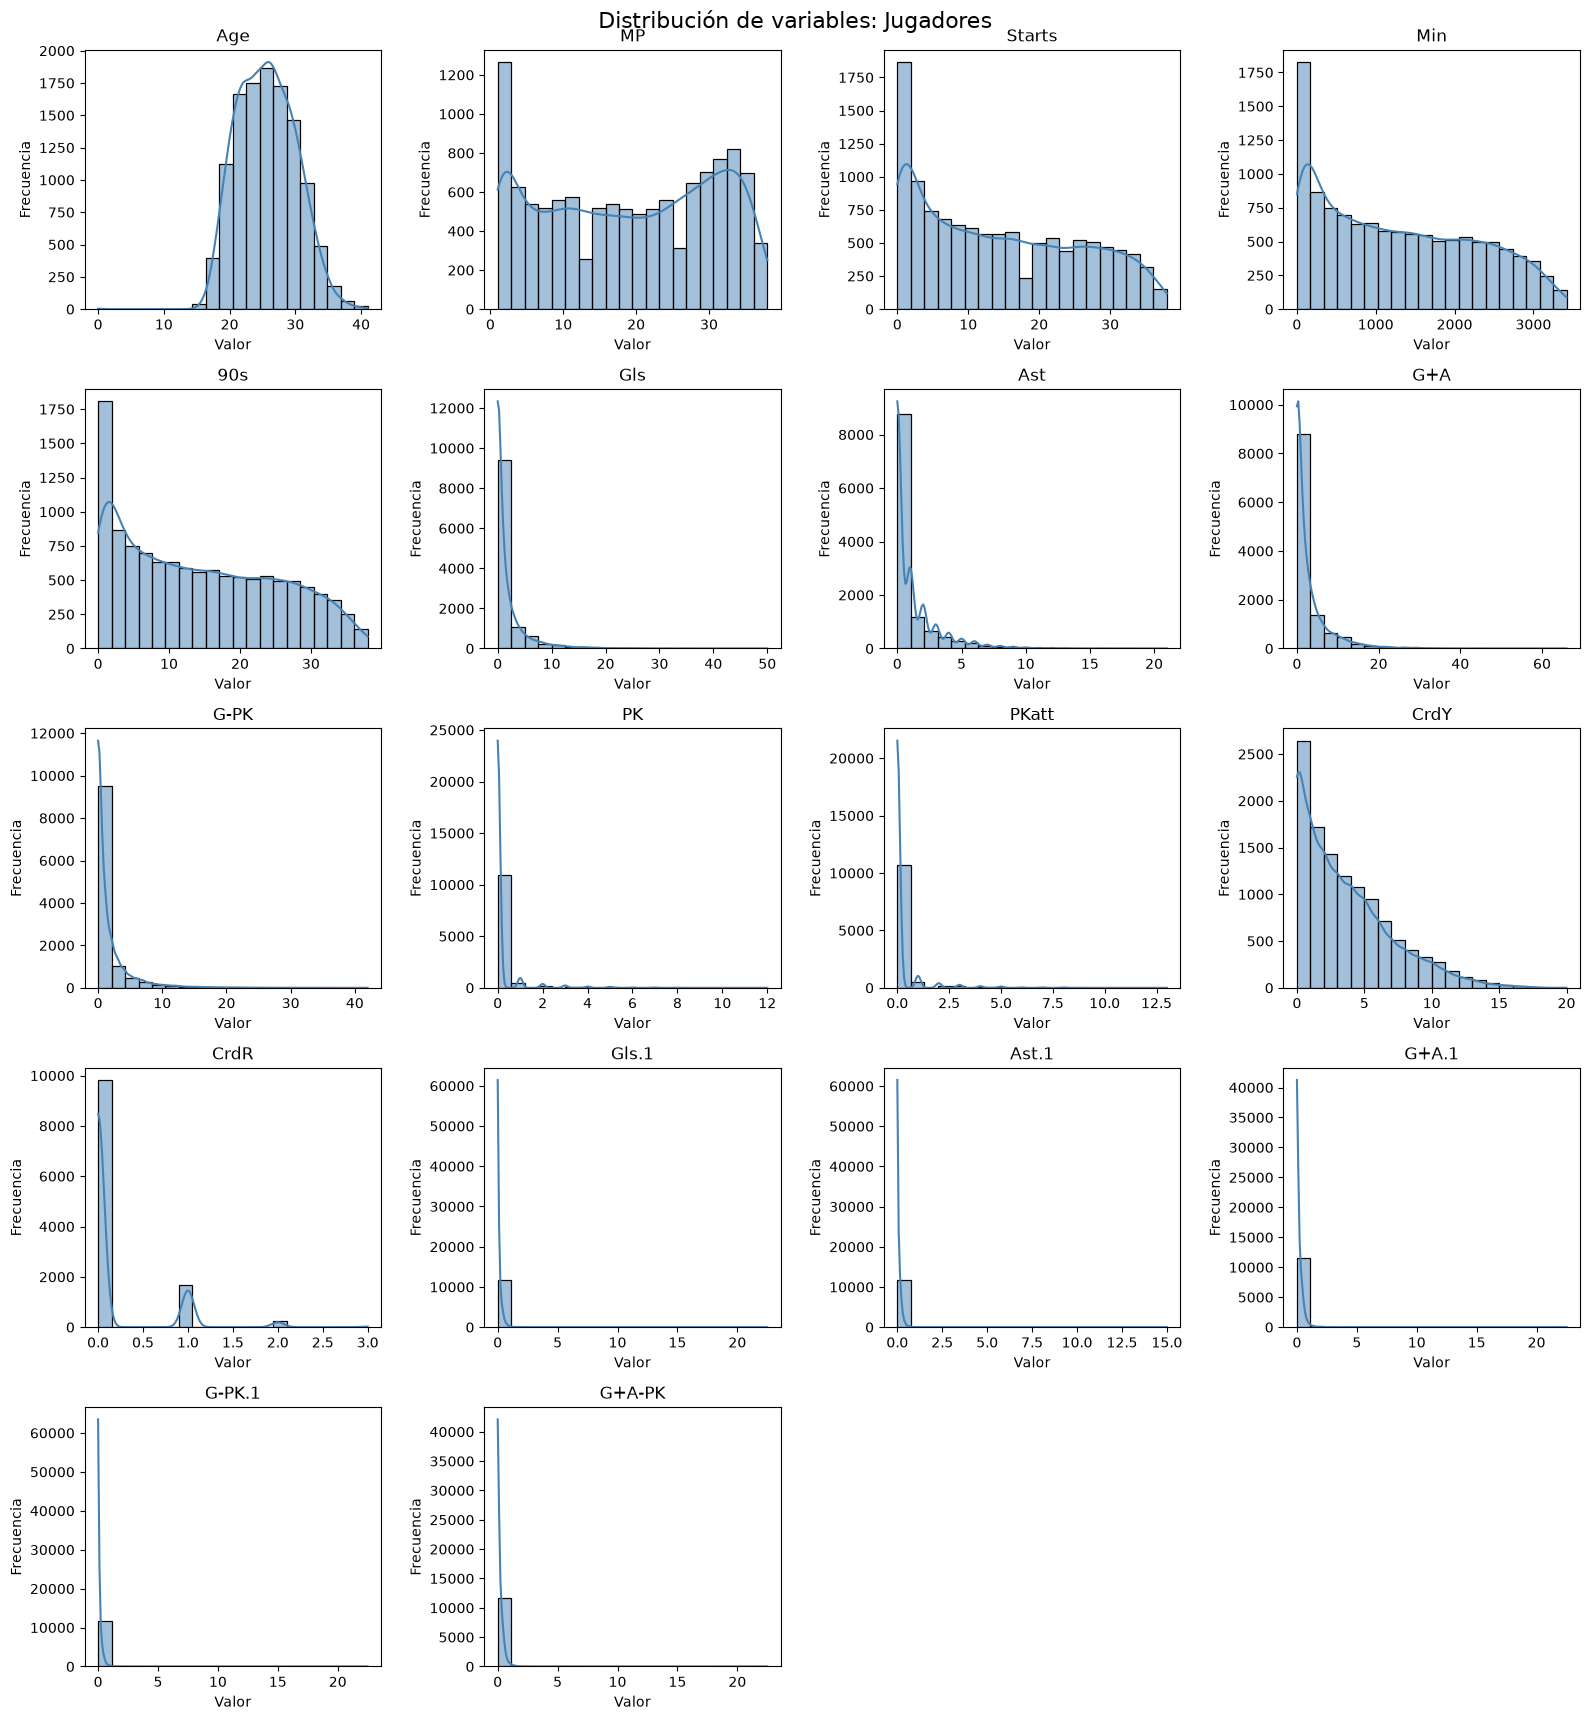

In [ ]:
print("Análisis de Distribución de las Variables")
# Selecciono las variables numéricas que pueden utilizarse en el análisis
columnas_excluir = {'Temporada', 'Rk', '# Pl', 'Born'}

tablas_ml = {
    'Partidos': df_partidos,
    'Equipos': df_equipos,
    'Tabla general': df_tabla,
    'Jugadores': df_jugadores
}

columnas_numericas = {}
for nombre, tabla in tablas_ml.items():
    columnas_numericas[nombre] = [
        columna for columna in tabla.select_dtypes(include='number').columns
        if columna not in columnas_excluir
    ]
    print(f"\n{nombre}: {len(columnas_numericas[nombre])} variables numéricas")
    print(', '.join(columnas_numericas[nombre]))

# Muestro un histograma por cada variable numérica de cada tabla
for nombre, tabla in tablas_ml.items():
    columnas = columnas_numericas[nombre]
    if not columnas:
        print(f"\n{nombre}: no tiene variables numéricas para graficar")
        continue

    numero_columnas = 4
    numero_filas = int(np.ceil(len(columnas) / numero_columnas))
    figura, ejes = plt.subplots(
        numero_filas, numero_columnas,
        figsize=(16, 3.5 * numero_filas),
        squeeze=False
    )
    figura.suptitle(f'Distribución de variables: {nombre}', fontsize=16)
    ejes = ejes.ravel()

    for eje, columna in zip(ejes, columnas):
        sns.histplot(data=tabla, x=columna, bins=20, kde=True, ax=eje, color='steelblue')
        eje.set_title(columna)
        eje.set_xlabel('Valor')
        eje.set_ylabel('Frecuencia')

    for eje in ejes[len(columnas):]:
        eje.remove()

    figura.tight_layout()
    plt.show()

## 4. Ingeniería de variables sin fuga de información

### El problema: la fuga de información (*data leakage*)

Una primera idea sería usar las estadísticas de toda la temporada de cada equipo. El problema es que esas estadísticas **incluyen partidos que todavía no se habían jugado** en la fecha del partido que queremos predecir. El modelo estaría "viendo el futuro" y los resultados se verían mucho mejores de lo que en realidad son.

### La solución: forma reciente (*rolling*)

Para cada partido calculamos, **solo con partidos anteriores**, las siguientes variables para el local y el visitante:

| Variable | Significado |
| --- | --- |
| `GF_rolling5` | Promedio de goles a favor en los últimos 5 partidos. |
| `GA_rolling5` | Promedio de goles en contra en los últimos 5 partidos. |
| `Pts_rolling5` | Promedio de puntos en los últimos 5 partidos. |
| `VenuePts_rolling5` | Promedio de puntos en los últimos 5 partidos **en esa misma condición** (de local o de visitante). |
| `MP_previos` | Partidos jugados en la temporada antes de este. |
| `Dif_*` | Diferencia local − visitante de cada variable anterior. |

En total son **15 variables** por partido (5 del local, 5 del visitante y 5 diferencias).

**Detalles importantes:**
- La forma reciente **se arrastra entre temporadas**: el primer partido de una temporada usa los últimos 5 partidos de la anterior.
- Los **equipos recién ascendidos** no tienen historial en Primera. Para ellos usamos como punto de partida el rendimiento de equipos que ascendieron en temporadas **anteriores**, que es una aproximación razonable de cómo le va a un equipo recién ascendido.

In [ ]:
if "Date" not in df_partidos.columns:
    raise ValueError("df_partidos necesita la columna Date para ordenar cronologicamente.")

columnas_estadisticas = [
    columna for columna in df_equipos.select_dtypes(include="number").columns
    if columna != "Temporada"
]
columnas_rolling = [
    "GF_rolling5", "GA_rolling5", "Pts_rolling5",
    "VenuePts_rolling5", "MP_previos"
]
columnas_X = [
    f"{columna}_{lado}"
    for lado in ("Home", "Away")
    for columna in columnas_rolling
] + [f"Dif_{columna}" for columna in columnas_rolling]


def _promedio_ultimos(valores):
    return float(np.mean(valores[-5:])) if valores else 0.0



def construir_matriz_rolling(partidos):
    """Construye estadisticas previas y conserva forma reciente entre temporadas."""
    requeridas = {"Temporada", "Date", "Home", "Away", "Goles_Local", "Goles_Visita", "Puntos_Local", "Puntos_Visita"}
    faltantes = requeridas - set(partidos.columns)
    if faltantes:
        raise ValueError(f"Faltan columnas en partidos: {sorted(faltantes)}")

    base = partidos.copy().reset_index(drop=True)
    base["_Fecha"] = pd.to_datetime(base["Date"], errors="coerce")
    if base["_Fecha"].isna().any():
        raise ValueError("Hay fechas invalidas en df_partidos.")
    base = base.sort_values(["Temporada", "_Fecha", "Home", "Away"]).reset_index(drop=True)
    base["_match_id"] = np.arange(len(base))
    base["_jugado"] = base["Puntos_Local"].notna() & base["Puntos_Visita"].notna()

    temporadas = sorted(base["Temporada"].unique())
    primera_temporada = temporadas[0]
    equipos_por_temporada = {
        temporada: set(base.loc[base["Temporada"] == temporada, "Home"])
        | set(base.loc[base["Temporada"] == temporada, "Away"])
        for temporada in temporadas
    }
    promovidos_por_temporada = {}
    for temporada in temporadas:
        if temporada == primera_temporada:
            promovidos_por_temporada[temporada] = set()
        else:
            promovidos_por_temporada[temporada] = (
                equipos_por_temporada[temporada] - equipos_por_temporada.get(temporada - 1, set())
            )

    # Semillas calculadas solo con equipos ascendidos de temporadas anteriores.
    semilla_por_temporada = {}
    historiales_previos = []
    for temporada in temporadas:
        semilla = [registro for registro in historiales_previos]
        semilla_por_temporada[temporada] = semilla
        filas_temporada = base[base["Temporada"] == temporada]
        for _, fila in filas_temporada.iterrows():
            if not bool(fila["_jugado"]):
                continue
            if fila["Home"] in promovidos_por_temporada[temporada]:
                historiales_previos.extend([
                    (float(fila["Goles_Local"]), float(fila["Goles_Visita"]), float(fila["Puntos_Local"]))
                ])
            if fila["Away"] in promovidos_por_temporada[temporada]:
                historiales_previos.extend([
                    (float(fila["Goles_Visita"]), float(fila["Goles_Local"]), float(fila["Puntos_Visita"]))
                ])

    historiales = {}
    historiales_venue = {}
    mp_temporada = {}
    features = []

    for temporada in temporadas:
        equipos = equipos_por_temporada[temporada]
        semilla = semilla_por_temporada[temporada]
        for equipo in equipos:
            if equipo not in historiales and semilla:
                historiales[equipo] = list(semilla[-5:])
                historiales_venue[(equipo, "Home")] = [registro[2] for registro in semilla[-5:]]
                historiales_venue[(equipo, "Away")] = [registro[2] for registro in semilla[-5:]]
            mp_temporada[(temporada, equipo)] = 0

        filas_temporada = base[base["Temporada"] == temporada]
        for _, fila in filas_temporada.iterrows():
            for lado, equipo, venue in (("Home", fila["Home"], "Home"), ("Away", fila["Away"], "Away")):
                historial = historiales.get(equipo, [])
                historial_venue = historiales_venue.get((equipo, venue), [])
                features.append({
                    "_match_id": fila["_match_id"],
                    "Temporada": temporada,
                    "Team": equipo,
                    "Venue": venue,
                    "GF_rolling5": _promedio_ultimos([x[0] for x in historial]),
                    "GA_rolling5": _promedio_ultimos([x[1] for x in historial]),
                    "Pts_rolling5": _promedio_ultimos([x[2] for x in historial]),
                    "VenuePts_rolling5": _promedio_ultimos(historial_venue),
                    "MP_previos": mp_temporada[(temporada, equipo)],
                })

            if bool(fila["_jugado"]):
                for equipo, venue, gf, ga, pts in (
                    (fila["Home"], "Home", fila["Goles_Local"], fila["Goles_Visita"], fila["Puntos_Local"]),
                    (fila["Away"], "Away", fila["Goles_Visita"], fila["Goles_Local"], fila["Puntos_Visita"]),
                ):
                    historiales.setdefault(equipo, []).append((float(gf), float(ga), float(pts)))
                    historiales[equipo] = historiales[equipo][-5:]
                    historiales_venue.setdefault((equipo, venue), []).append(float(pts))
                    historiales_venue[(equipo, venue)] = historiales_venue[(equipo, venue)][-5:]
                    mp_temporada[(temporada, equipo)] += 1

    eventos = pd.DataFrame(features)
    home = eventos[eventos["Venue"] == "Home"].drop(columns="Venue").rename(
        columns={"Team": "Home", **{c: f"{c}_Home" for c in columnas_rolling}}
    )
    away = eventos[eventos["Venue"] == "Away"].drop(columns="Venue").rename(
        columns={"Team": "Away", **{c: f"{c}_Away" for c in columnas_rolling}}
    )
    salida = base.merge(home, on=["_match_id", "Temporada", "Home"], validate="one_to_one")
    salida = salida.merge(away, on=["_match_id", "Temporada", "Away"], validate="one_to_one")
    for columna in columnas_rolling:
        salida[f"Dif_{columna}"] = salida[f"{columna}_Home"] - salida[f"{columna}_Away"]

    assert salida[columnas_X].notna().all().all()
    return salida.sort_values("_match_id").reset_index(drop=True)

## 5. Variable objetivo y división temporal

- **Objetivo (`y`):** el resultado del partido visto desde el **equipo local**: `Derrota`, `Empate` o `Victoria`.
- **División temporal:** en fútbol no tiene sentido revolver partidos al azar entre entrenamiento y prueba, porque el modelo aprendería de partidos posteriores. Por eso entrenamos con **todas las temporadas anteriores a 2025** y probamos con la **temporada 2025/26 completa** (380 partidos), como si estuviéramos prediciendo una temporada nueva.

Los partidos de 2026/27 que ya se jugaron no entran en entrenamiento ni en prueba; se usan después para calcular la forma actual de los equipos.

In [ ]:
print("--- Matriz ML sin fuga: variables rolling previas al partido ---")

matriz_ml = construir_matriz_rolling(df_partidos)
# Nos quedamos solo con partidos ya jugados (los pendientes no tienen resultado)
matriz_ml = matriz_ml.dropna(subset=["Puntos_Local", "Puntos_Visita"]).copy()
X = matriz_ml[columnas_X]
# Target desde la perspectiva del local: 0 pts = Derrota, 1 = Empate, 3 = Victoria
encoder = LabelEncoder().fit([0, 1, 3])
y = encoder.transform(matriz_ml["Puntos_Local"].astype(int))
target_names = ["Derrota", "Empate", "Victoria"]

# Split temporal: entrenamos con todo lo anterior a 2025 y probamos con la temporada 2025.
# El escalador se ajusta SOLO con entrenamiento para no filtrar informacion de prueba.
mask_train = matriz_ml["Temporada"] < 2025
mask_test = matriz_ml["Temporada"] == 2025
scaler = StandardScaler()
X_train = scaler.fit_transform(X.loc[mask_train])
X_test = scaler.transform(X.loc[mask_test])
y_train = y[mask_train.to_numpy()]
y_test = y[mask_test.to_numpy()]
print(f"Matriz rolling: {matriz_ml.shape[0]} partidos | entrenamiento: {mask_train.sum()} | prueba 2025: {mask_test.sum()}")

--- Matriz ML sin fuga: variables rolling previas al partido ---
Matriz rolling: 7720 partidos | entrenamiento: 7220 | prueba 2025: 380


In [ ]:
# Funcion auxiliar: entrena un modelo, lo evalua en 2025 y guarda sus metricas para compararlo.
resultados_modelos = []
modelos_entrenados = {}
def evaluar_modelo(nombre, modelo):
    modelo.fit(X_train, y_train)
    predicciones = modelo.predict(X_test)
    reporte = classification_report(y_test, predicciones, target_names=target_names, output_dict=True, zero_division=0)
    resultados_modelos.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, predicciones),
        "Precision macro": reporte["macro avg"]["precision"],
        "Recall macro": reporte["macro avg"]["recall"],
        "F1 macro": reporte["macro avg"]["f1-score"]
    })
    modelos_entrenados[nombre] = modelo
    print(f"\n--- {nombre} ---")
    display(pd.DataFrame(reporte).T.round(3))

## 6. Comparación de modelos base

Probamos cinco algoritmos de clasificación con sus parámetros por defecto, para tener un punto de comparación:

| Modelo | Idea general |
| --- | --- |
| **Naive Bayes** | Calcula probabilidades con el Teorema de Bayes, suponiendo que las variables son independientes entre sí. |
| **Regresión Logística** | Modelo lineal que convierte una combinación de variables en probabilidades. Es el *baseline* estadístico clásico. |
| **Árbol de Decisión** | Aprende reglas del tipo "si / entonces" partiendo los datos en grupos. |
| **Random Forest** | Promedia la opinión de cientos de árboles entrenados con muestras distintas. |
| **XGBoost** | Entrena árboles en secuencia, cada uno corrigiendo los errores del anterior. |

Para cada modelo mostramos *precision*, *recall* y *F1* por clase en la temporada de prueba.

### 6.1 Naive Bayes

In [ ]:
modelo_naive_bayes = GaussianNB()
evaluar_modelo('Naive Bayes', modelo_naive_bayes)


--- Naive Bayes ---


,precision,recall,f1-score,support
Derrota,0.366,0.406,0.385,101.000
Empate,0.266,0.183,0.217,93.000
Victoria,0.593,0.651,0.621,186.000
accuracy,0.471,0.471,0.471,0.471
macro avg,0.408,0.413,0.407,380.000
weighted avg,0.453,0.471,0.459,380.000


### 6.2 Regresión Logística

In [ ]:
modelo_logistico = LogisticRegression(max_iter=1000, random_state=42)
evaluar_modelo('Regresion Logistica', modelo_logistico)


--- Regresion Logistica ---


,precision,recall,f1-score,support
Derrota,0.406,0.277,0.329,101.000
Empate,0.333,0.011,0.021,93.000
Victoria,0.536,0.887,0.668,186.000
accuracy,0.511,0.511,0.511,0.511
macro avg,0.425,0.392,0.339,380.000
weighted avg,0.452,0.511,0.420,380.000


### 6.3 Árbol de Decisión

In [ ]:
modelo_arbol = DecisionTreeClassifier(random_state=42)
evaluar_modelo('Arbol de Decision', modelo_arbol)


--- Arbol de Decision ---


,precision,recall,f1-score,support
Derrota,0.330,0.337,0.333,101.000
Empate,0.292,0.301,0.296,93.000
Victoria,0.514,0.500,0.507,186.000
accuracy,0.408,0.408,0.408,0.408
macro avg,0.379,0.379,0.379,380.000
weighted avg,0.411,0.408,0.409,380.000


### 6.4 Random Forest

In [ ]:
modelo_random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
evaluar_modelo('Random Forest', modelo_random_forest)


--- Random Forest ---


,precision,recall,f1-score,support
Derrota,0.312,0.248,0.276,101.000
Empate,0.359,0.151,0.212,93.000
Victoria,0.513,0.720,0.600,186.000
accuracy,0.455,0.455,0.455,0.455
macro avg,0.395,0.373,0.363,380.000
weighted avg,0.422,0.455,0.419,380.000


### 6.5 XGBoost

In [ ]:
modelo_xgboost = XGBClassifier(
    eval_metric='mlogloss',
    random_state=42
)
evaluar_modelo('XGBoost', modelo_xgboost)


--- XGBoost ---


,precision,recall,f1-score,support
Derrota,0.326,0.277,0.299,101.000
Empate,0.204,0.108,0.141,93.000
Victoria,0.535,0.704,0.608,186.000
accuracy,0.445,0.445,0.445,0.445
macro avg,0.355,0.363,0.349,380.000
weighted avg,0.398,0.445,0.412,380.000


### 6.6 Comparación de los modelos base

--- Comparacion final de modelos ---


,Modelo,Accuracy,Precision macro,Recall macro,F1 macro
0,Naive Bayes,0.471,0.408,0.413,0.407
1,Arbol de Decision,0.408,0.379,0.379,0.379
2,Random Forest,0.455,0.395,0.373,0.363
3,XGBoost,0.445,0.355,0.363,0.349
4,Regresion Logistica,0.511,0.425,0.392,0.339


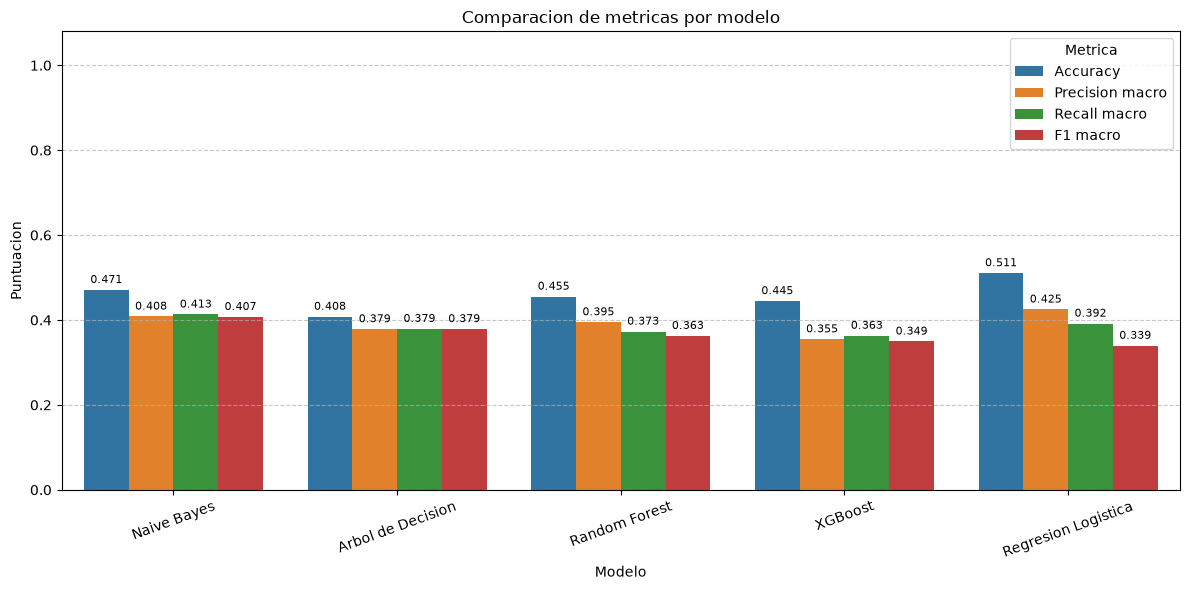

In [ ]:
print("--- Comparacion final de modelos ---")
df_resultados = pd.DataFrame(resultados_modelos).sort_values(
    by="F1 macro",
    ascending=False
).reset_index(drop=True)
display(df_resultados.style.format({
    "Accuracy": "{:.3f}",
    "Precision macro": "{:.3f}",
    "Recall macro": "{:.3f}",
    "F1 macro": "{:.3f}"
}))

metricas_grafica = df_resultados.melt(
    id_vars="Modelo",
    value_vars=["Accuracy", "Precision macro", "Recall macro", "F1 macro"],
    var_name="Metrica",
    value_name="Valor"
)
plt.figure(figsize=(12, 6))
eje = sns.barplot(data=metricas_grafica, x="Modelo", y="Valor", hue="Metrica")
for grupo_barras in eje.containers:
    eje.bar_label(grupo_barras, fmt="%.3f", padding=3, fontsize=8)
plt.ylim(0, 1.08)
plt.title("Comparacion de metricas por modelo")
plt.ylabel("Puntuacion")
plt.xlabel("Modelo")
plt.xticks(rotation=20)
plt.legend(title="Metrica")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### ¿Qué nos dicen estos resultados?

| Modelo | Accuracy | F1 macro |
| --- | --- | --- |
| Naive Bayes | 0.471 | **0.407** |
| Árbol de Decisión | 0.408 | 0.379 |
| Random Forest | 0.455 | 0.363 |
| XGBoost | 0.445 | 0.349 |
| Regresión Logística | **0.511** | 0.339 |

- **La referencia a vencer:** en la temporada de prueba el local ganó **186 de 380 partidos (48.9 %)**. Un "modelo" que siempre diga *gana el local* ya acierta casi la mitad. Solo la **Regresión Logística (51.1 %)** supera esa referencia, y por poco.
- **El empate es el resultado más difícil.** La Regresión Logística casi nunca predice empate (recall de **0.011**): aprende que lo más seguro es apostar por la victoria local. Por eso tiene el mejor *accuracy* pero un F1 macro bajo.
- **Naive Bayes** tiene el mejor F1 macro porque se arriesga más a predecir empates y derrotas, aunque acierta menos en total.
- **El Árbol de Decisión** es el peor: sin límite de profundidad memoriza el entrenamiento (*overfitting*) y no generaliza.
- Los modelos más complejos (**Random Forest** y **XGBoost**) **no superan** a los simples: con 15 variables de forma reciente no hay relaciones tan complicadas que solo un modelo complejo pueda capturar.

### Nota: ideas para mejorar los modelos

De esta primera comparación salieron varias ideas:

- Agregar la **forma reciente** de los equipos, su rendimiento **como local y como visitante**, y sus **goles a favor y en contra** antes de cada partido. *(Ya están incluidas en la matriz rolling.)*
- Usar **diferencias entre los equipos** (goles, posesión, edad, producción ofensiva) en vez de solo los valores absolutos. *(Incluido con las variables `Dif_*`.)*
- Calcular todo **solo con información disponible antes del partido**, para no hacer trampa con datos del futuro.
- Después, **ajustar los parámetros** de los modelos y fijarnos en la calidad de las **probabilidades**, no solo en el acierto.

## 7. Pipeline final: modelos multiclase calibrados

Para proyectar una temporada no basta con saber **qué resultado es más probable**; necesitamos **probabilidades confiables** de los tres resultados. Si el modelo dice "60 % de victoria local", en el largo plazo el local debería ganar aproximadamente 6 de cada 10 de esos partidos.

Para lograrlo:
1. Tomamos los tres mejores candidatos (**Regresión Logística, Random Forest y XGBoost**), estos dos últimos con parámetros más conservadores para evitar *overfitting*.
2. Los **calibramos** con `CalibratedClassifierCV` (método *sigmoid* con validación cruzada de 5 particiones), que ajusta las probabilidades para que se parezcan a las frecuencias reales.
3. Los comparamos con métricas de probabilidad:
   - **Log loss:** castiga mucho dar una probabilidad alta a un resultado que no ocurre. Menor es mejor. Como referencia, asignar 1/3 a cada resultado da **1.0986**.
   - **Brier score:** error cuadrático promedio entre la probabilidad y lo que pasó (0 = perfecto). Menor es mejor.

El modelo con **menor log loss** es el que usamos para la proyección.

In [ ]:
# Separamos temporalmente: entrenamos antes de 2025 y validamos en 2025.
matriz_final = matriz_ml.sort_values(["Temporada", "_Fecha", "_match_id"]).reset_index(drop=True)
train_final = matriz_final[matriz_final["Temporada"] < 2025].copy()
valid_final = matriz_final[matriz_final["Temporada"] == 2025].copy()
if train_final.empty or valid_final.empty:
    raise ValueError("No hay datos suficientes para el split temporal solicitado.")

scaler_final = StandardScaler()
X_train_final = scaler_final.fit_transform(train_final[columnas_X])
X_valid_final = scaler_final.transform(valid_final[columnas_X])
y_train_final = train_final["Puntos_Local"].astype(int).to_numpy()
y_valid_final = valid_final["Puntos_Local"].astype(int).to_numpy()
clases_final = np.array([0, 1, 3])
y_train_codificado = np.searchsorted(clases_final, y_train_final)

modelos_multiclase = {
    "Regresion Logistica": LogisticRegression(max_iter=2000, solver="lbfgs", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(
        objective="multi:softprob", num_class=3, eval_metric="mlogloss",
        n_estimators=250, max_depth=4, learning_rate=0.05,
        subsample=0.9, colsample_bytree=0.9, random_state=42
    )
}

modelos_calibrados_final = {}
metricas_finales = []

def brier_multiclase(y_real, probabilidades):
    """Promedio del Brier one-vs-rest para las tres clases."""
    return float(np.mean([
        brier_score_loss((y_real == clase).astype(int), probabilidades[:, i])
        for i, clase in enumerate(clases_final)
    ]))

for nombre, base in modelos_multiclase.items():
    modelo = CalibratedClassifierCV(estimator=base, method="sigmoid", cv=5)
    modelo.fit(X_train_final, y_train_codificado)
    probabilidades = modelo.predict_proba(X_valid_final)
    orden = list(modelo.classes_)
    probabilidades = probabilidades[:, [orden.index(clase) for clase in [0, 1, 2]]]
    predicciones = clases_final[probabilidades.argmax(axis=1)]
    modelos_calibrados_final[nombre] = modelo
    metricas_finales.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_valid_final, predicciones),
        "F1 macro": f1_score(y_valid_final, predicciones, labels=clases_final, average="macro", zero_division=0),
        "Log loss": log_loss(y_valid_final, probabilidades, labels=clases_final),
        "Brier multiclase": brier_multiclase(y_valid_final, probabilidades)
    })

df_metricas_multiclase = pd.DataFrame(metricas_finales).sort_values(
    ["Log loss", "Brier multiclase"]
).reset_index(drop=True)
print("Resultados de validacion temporal (entrenamiento < 2025, validacion 2025):")
display(df_metricas_multiclase.style.format({c: "{:.4f}" for c in ["Accuracy", "F1 macro", "Log loss", "Brier multiclase"]}))

mejor_modelo_nombre = df_metricas_multiclase.iloc[0]["Modelo"]
print("Modelo seleccionado:", mejor_modelo_nombre)

Resultados de validacion temporal (entrenamiento < 2025, validacion 2025):


,Modelo,Accuracy,F1 macro,Log loss,Brier multiclase
0,Regresion Logistica,0.5053,0.3275,1.0033,0.1999
1,XGBoost,0.5000,0.3105,1.0099,0.2012
2,Random Forest,0.4947,0.3194,1.0135,0.2022


Modelo seleccionado: Regresion Logistica


### Resultados de la validación (entrenamiento < 2025, prueba 2025)

| Modelo | Accuracy | F1 macro | Log loss | Brier |
| --- | --- | --- | --- | --- |
| **Regresión Logística** | **0.5053** | **0.3275** | **1.0033** | **0.1999** |
| XGBoost | 0.5000 | 0.3105 | 1.0099 | 0.2012 |
| Random Forest | 0.4947 | 0.3194 | 1.0135 | 0.2022 |

La **Regresión Logística** gana en todas las métricas. Su log loss (1.0033) mejora a la referencia de probabilidades iguales (1.0986): el modelo sí aporta información, aunque el margen muestra lo impredecible que es el fútbol. Los tres modelos quedan muy cerca, lo que confirma que **la información disponible, y no el algoritmo, es lo que limita el desempeño**.

## 8. Proyección de la temporada 2026/27

### 8.1 Reentrenamiento del modelo ganador

Una vez elegido el modelo, lo **reentrenamos con todos los partidos hasta la temporada 2025/26** para aprovechar la información más reciente antes de predecir la temporada en curso.

In [ ]:
# Reentrenamos el ganador con toda la informacion disponible hasta 2025.
antes_2026 = matriz_ml[matriz_ml["Temporada"] <= 2025].copy()
scaler_reentrenado = StandardScaler()
X_antes_2026 = scaler_reentrenado.fit_transform(antes_2026[columnas_X])
y_antes_2026 = antes_2026["Puntos_Local"].astype(int).to_numpy()
y_antes_2026_codificado = np.searchsorted(clases_final, y_antes_2026)
base_ganador = modelos_multiclase[mejor_modelo_nombre]
modelo_final_calibrado = CalibratedClassifierCV(
    estimator=base_ganador, method="sigmoid", cv=5
)
modelo_final_calibrado.fit(X_antes_2026, y_antes_2026_codificado)

### 8.2 Probabilidades de los partidos pendientes y puntos esperados

1. Juntamos el historial completo con los partidos de 2026/27 que **ya se jugaron** y los que **faltan por jugar**.
2. Recalculamos las variables de forma reciente con la información hasta hoy.
3. El modelo da, para cada partido pendiente, la probabilidad de **victoria local, empate y victoria visitante**.
4. Con esas probabilidades calculamos los **puntos esperados (xPts)**:

$$xPts_{local} = 3 \cdot P(\text{victoria}) + 1 \cdot P(\text{empate}) \qquad xPts_{visita} = 3 \cdot P(\text{derrota}) + 1 \cdot P(\text{empate})$$

Sumados a los puntos que cada equipo ya tiene, nos dan una primera estimación de los puntos finales.

In [ ]:
# Construimos las variables prepartido de 2026 con historial hasta el corte actual.
if "calendario_2026" not in globals():
    calendario_2026 = pd.read_csv(os.path.join(ruta_clean.replace("processed\\clean", "partidos"), "partidos2026.csv"))
for col in ("Home", "Away"):
    if col in calendario_2026.columns:
        calendario_2026[col] = calendario_2026[col].replace({"Dep. A Coruña": "Dep. La Coruña"})
if "Score" not in calendario_2026.columns:
    raise ValueError("calendario_2026 necesita la columna Score para identificar partidos pendientes.")

jugados_2026 = df_partidos[
    (df_partidos["Temporada"] == 2026)
    & df_partidos["Puntos_Local"].notna()
    & df_partidos["Puntos_Visita"].notna()
].copy()
if jugados_2026.empty:
    raise ValueError("No se encontraron partidos jugados de 2026 en df_partidos.")

pendientes_2026 = calendario_2026[
    calendario_2026["Score"].isna()
    & calendario_2026["Home"].notna()
    & calendario_2026["Away"].notna()
].copy()
pendientes_2026["Temporada"] = 2026
for columna in ["Goles_Local", "Goles_Visita", "Puntos_Local", "Puntos_Visita"]:
    pendientes_2026[columna] = np.nan

columnas_partidos = ["Temporada", "Date", "Home", "Away", "Goles_Local", "Goles_Visita", "Puntos_Local", "Puntos_Visita"]
historial_para_2026 = pd.concat([
    df_partidos[df_partidos["Temporada"] < 2026][columnas_partidos],
    jugados_2026[columnas_partidos],
    pendientes_2026[columnas_partidos]
], ignore_index=True)
matriz_2026_final = construir_matriz_rolling(historial_para_2026)
df_restante_final = matriz_2026_final[~matriz_2026_final["_jugado"]].copy()

X_restante_final = scaler_reentrenado.transform(df_restante_final[columnas_X])
probabilidades_restantes = modelo_final_calibrado.predict_proba(X_restante_final)
orden_final = list(modelo_final_calibrado.classes_)
probabilidades_restantes = probabilidades_restantes[:, [orden_final.index(clase) for clase in [0, 1, 2]]]
assert np.allclose(probabilidades_restantes.sum(axis=1), 1.0, atol=1e-10)

p_derrota = probabilidades_restantes[:, 0]
p_empate = probabilidades_restantes[:, 1]
p_victoria = probabilidades_restantes[:, 2]
df_restante_final["P_Derrota"] = p_derrota
df_restante_final["P_Empate"] = p_empate
df_restante_final["P_Victoria"] = p_victoria
df_restante_final["xPts_Local"] = 3 * p_victoria + p_empate
df_restante_final["xPts_Visita"] = 3 * p_derrota + p_empate

# Tabla actual y puntos esperados medios antes de la simulacion.
tabla_actual_2026 = df_tabla[df_tabla["Temporada"] == 2026][["Squad", "MP", "Pts", "Rk"]].copy()
tabla_actual_2026 = tabla_actual_2026.rename(columns={"Pts": "Pts_Actuales", "Rk": "Posicion_Actual"})
if tabla_actual_2026.empty:
    raise ValueError("No existe tabla actual para la temporada 2026.")

xpts_local_final = df_restante_final.groupby("Home", as_index=False)["xPts_Local"].sum().rename(columns={"Home": "Squad", "xPts_Local": "xPts_Restantes_Local"})
xpts_visitante_final = df_restante_final.groupby("Away", as_index=False)["xPts_Visita"].sum().rename(columns={"Away": "Squad", "xPts_Visita": "xPts_Restantes_Visitante"})
xpts_final = xpts_local_final.merge(xpts_visitante_final, on="Squad", how="outer").fillna(0)
xpts_final["xPts_Restantes"] = xpts_final["xPts_Restantes_Local"] + xpts_final["xPts_Restantes_Visitante"]

xpts_promedio_final = tabla_actual_2026.merge(xpts_final[["Squad", "xPts_Restantes"]], on="Squad", how="left").fillna({"xPts_Restantes": 0})
xpts_promedio_final["xPts_Promedio_Final"] = xpts_promedio_final["Pts_Actuales"] + xpts_promedio_final["xPts_Restantes"]

## 9. Simulación Monte Carlo

Los puntos esperados dan un promedio, pero no dicen **qué tan probable** es que un equipo sea campeón o descienda. Para eso usamos una **simulación Monte Carlo**:

1. Para cada uno de los **260 partidos pendientes** sorteamos un resultado según las probabilidades del modelo (por ejemplo, si el local tiene 50 % / 25 % / 25 %, ganará en la mitad de las simulaciones).
2. Sumamos los puntos y armamos la tabla final de esa temporada simulada (los empates en puntos se rompen al azar).
3. Repetimos el proceso **500,000 veces**.

Al final contamos en cuántas simulaciones cada equipo terminó **1.º (campeón)**, **entre los 4 primeros (Champions)** o **entre los 3 últimos (descenso)**, y calculamos un **intervalo del 90 %** para sus puntos finales.

In [ ]:
# Monte Carlo de resultados independientes por partido.
n_simulaciones = 500000
equipos = tabla_actual_2026["Squad"].to_numpy()
puntos_base = dict(zip(tabla_actual_2026["Squad"], tabla_actual_2026["Pts_Actuales"]))
historial_puntos = {equipo: np.zeros(n_simulaciones) for equipo in equipos}
historial_posiciones = {equipo: np.zeros(n_simulaciones) for equipo in equipos}
locales = df_restante_final["Home"].to_numpy()
visitantes = df_restante_final["Away"].to_numpy()
rng = np.random.default_rng(42)

for sim in range(n_simulaciones):
    puntos = puntos_base.copy()
    aleatorios = rng.random(len(df_restante_final))
    acumuladas = np.cumsum(probabilidades_restantes, axis=1)
    resultados = np.sum(aleatorios[:, None] > acumuladas, axis=1)
    for i, resultado in enumerate(resultados):
        if resultado == 2:
            puntos[locales[i]] += 3
        elif resultado == 1:
            puntos[locales[i]] += 1
            puntos[visitantes[i]] += 1
        else:
            puntos[visitantes[i]] += 3
    tabla_sim = pd.DataFrame({"Squad": list(puntos), "Pts": list(puntos.values())})
    tabla_sim["Desempate"] = rng.random(len(equipos))
    tabla_sim = tabla_sim.sort_values(["Pts", "Desempate"], ascending=[False, False]).reset_index(drop=True)
    for posicion, fila in enumerate(tabla_sim.itertuples(index=False), start=1):
        historial_puntos[fila.Squad][sim] = fila.Pts
        historial_posiciones[fila.Squad][sim] = posicion

resumen_mc = []
for equipo in equipos:
    pts = historial_puntos[equipo]
    posiciones = historial_posiciones[equipo]
    resumen_mc.append({
        "Squad": equipo,
        "Pts_Actuales": puntos_base[equipo],
        "xPts_Promedio_Final": pts.mean(),
        "IC90_Pts_5": np.percentile(pts, 5),
        "IC90_Pts_95": np.percentile(pts, 95),
        "Prob_Campeon_%": 100 * np.mean(posiciones == 1),
        "Prob_Champions_%": 100 * np.mean(posiciones <= 4),
        "Prob_Descenso_%": 100 * np.mean(posiciones >= 18),
    })

df_montecarlo = pd.DataFrame(resumen_mc).sort_values("xPts_Promedio_Final", ascending=False).reset_index(drop=True)
df_montecarlo.insert(0, "Posicion_Proyectada", np.arange(1, len(df_montecarlo) + 1))

print(f"Simulaciones Monte Carlo: {n_simulaciones}")
print(f"Partidos pendientes simulados: {len(df_restante_final)}")
print(f"Modelo final: {mejor_modelo_nombre}")
display(df_montecarlo.style.format({
    "Pts_Actuales": "{:.0f}", "xPts_Promedio_Final": "{:.2f}",
    "IC90_Pts_5": "{:.2f}", "IC90_Pts_95": "{:.2f}",
    "Prob_Campeon_%": "{:.2f}%", "Prob_Champions_%": "{:.2f}%", "Prob_Descenso_%": "{:.2f}%"
}).set_table_styles([
    {"selector": "th", "props": [("background-color", "#e30613"), ("color", "white"), ("font-weight", "bold")]},
    {"selector": "td", "props": [("background-color", "#161616"), ("color", "white")]},
    {"selector": "table", "props": [("border-collapse", "collapse"), ("font-family", "Arial")]}
]))

Simulaciones Monte Carlo: 500000
Partidos pendientes simulados: 260
Modelo final: Regresion Logistica


,Posicion_Proyectada,Squad,Pts_Actuales,xPts_Promedio_Final,IC90_Pts_5,IC90_Pts_95,Prob_Campeon_%,Prob_Champions_%,Prob_Descenso_%
0,1,Barcelona,33,88.60,78.00,98.00,75.40%,99.92%,0.00%
1,2,Real Madrid,30,82.08,72.00,92.00,22.60%,99.03%,0.00%
2,3,Atlético Madrid,28,69.96,59.00,81.00,0.95%,72.47%,0.00%
3,4,Real Betis,26,69.63,59.00,80.00,0.76%,70.78%,0.00%
4,5,Real Sociedad,22,66.37,56.00,77.00,0.28%,49.11%,0.00%
5,6,Athletic Club,16,56.04,46.00,67.00,0.00%,5.52%,0.22%
6,7,Sevilla,18,52.13,42.00,63.00,0.00%,1.75%,1.11%
7,8,Villarreal,15,48.59,38.00,59.00,0.00%,0.50%,3.92%
8,9,Dep. A Coruña,15,48.24,38.00,59.00,0.00%,0.38%,4.20%
9,10,Racing Sant,14,46.36,36.00,57.00,0.00%,0.20%,7.00%


## 10. Visualización de resultados

- **Izquierda:** puntos finales esperados de cada equipo; la línea blanca marca el rango donde cae el 90 % de las simulaciones.
- **Derecha:** probabilidad de cada equipo de ser campeón, clasificar a Champions o descender.

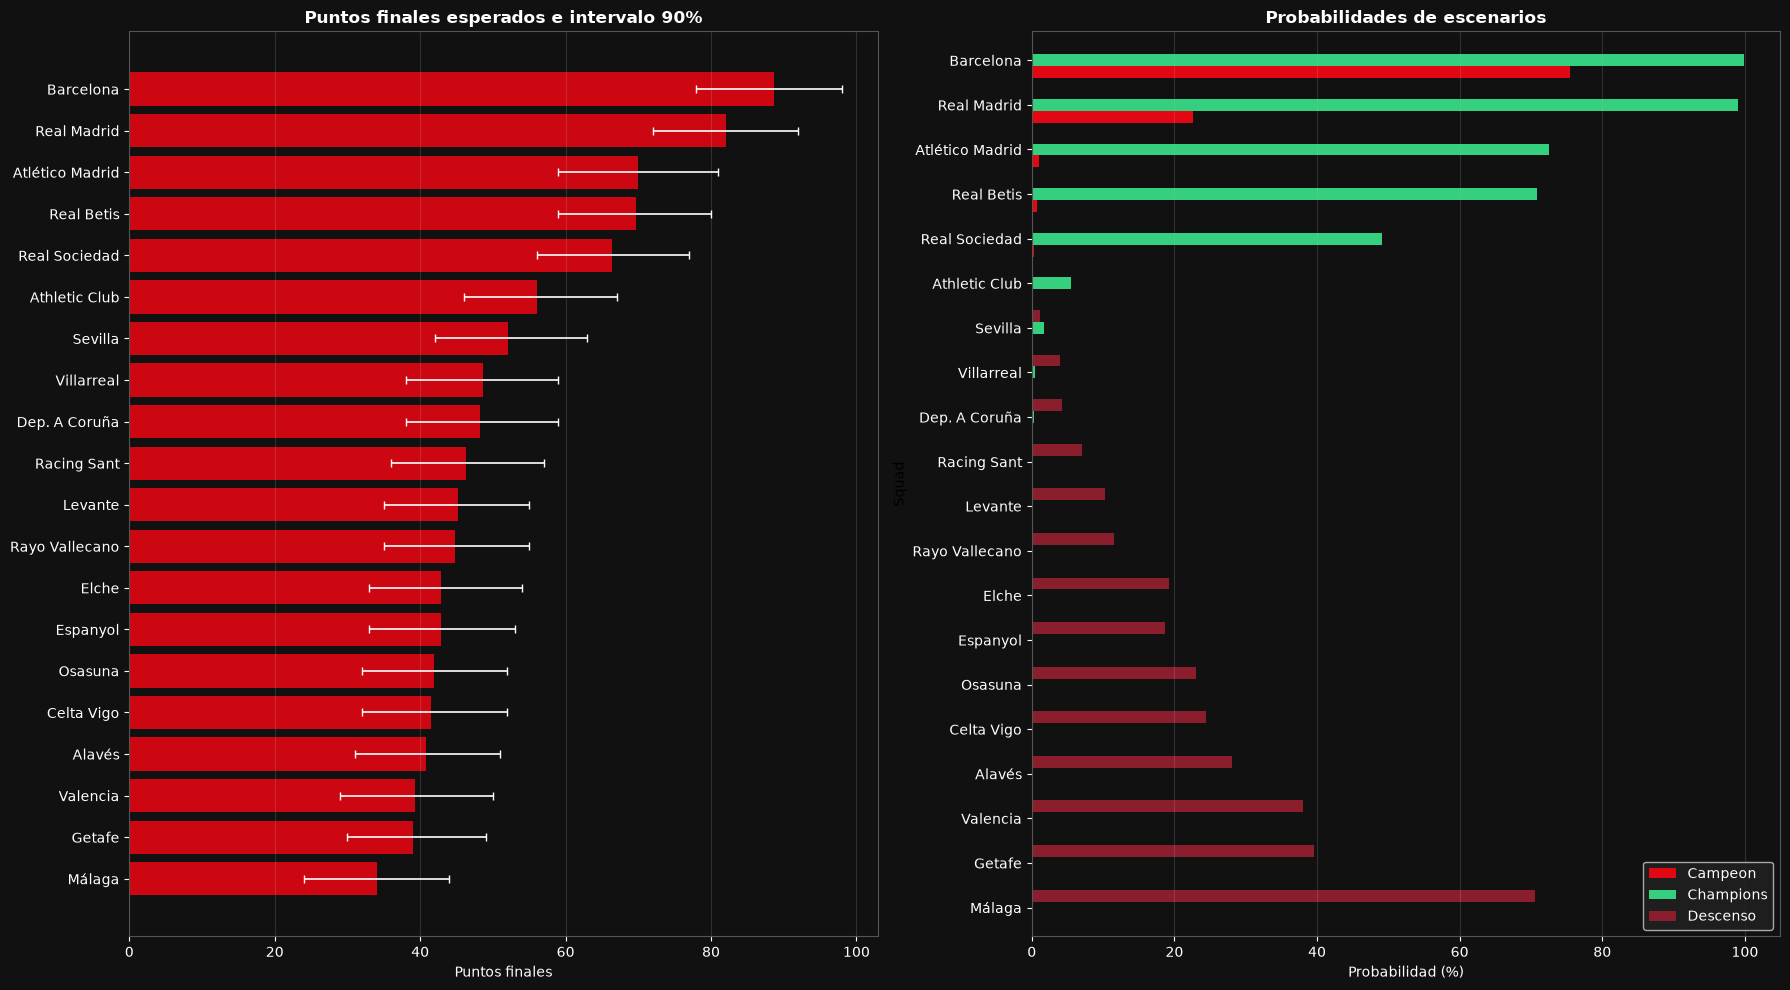

In [ ]:
# Visualizacion final de puntos esperados, rangos y probabilidades.
datos_grafica = df_montecarlo.sort_values("xPts_Promedio_Final", ascending=True).copy()
fig, ejes = plt.subplots(1, 2, figsize=(18, 10), facecolor="#111111")

# Puntos esperados con intervalo de confianza del 90%.
ejes[0].set_facecolor("#111111")
y = np.arange(len(datos_grafica))
media = datos_grafica["xPts_Promedio_Final"].to_numpy()
error_inferior = media - datos_grafica["IC90_Pts_5"].to_numpy()
error_superior = datos_grafica["IC90_Pts_95"].to_numpy() - media
ejes[0].barh(y, media, color="#E30613", alpha=0.9)
ejes[0].errorbar(media, y, xerr=[error_inferior, error_superior], fmt="none", ecolor="white", capsize=3, linewidth=1.2)
ejes[0].set_yticks(y, datos_grafica["Squad"])
ejes[0].set_title("Puntos finales esperados e intervalo 90%", color="white", fontweight="bold")
ejes[0].set_xlabel("Puntos finales", color="white")
ejes[0].tick_params(colors="white")
ejes[0].grid(axis="x", alpha=0.2)

# Probabilidades de campeonato, Champions y descenso.
datos_prob = datos_grafica.set_index("Squad")[["Prob_Campeon_%", "Prob_Champions_%", "Prob_Descenso_%"]]
datos_prob.plot.barh(
    ax=ejes[1], color=["#E30613", "#35D07F", "#8B1E2D"], width=0.8
)
ejes[1].set_facecolor("#111111")
ejes[1].set_title("Probabilidades de escenarios", color="white", fontweight="bold")
ejes[1].set_xlabel("Probabilidad (%)", color="white")
ejes[1].tick_params(colors="white")
ejes[1].legend(["Campeon", "Champions", "Descenso"], facecolor="#222222", labelcolor="white")
ejes[1].grid(axis="x", alpha=0.2)
for eje in ejes:
    for borde in eje.spines.values():
        borde.set_color("#555555")
plt.tight_layout()
plt.show()

### Probabilidades por equipo

In [ ]:
# Lista de probabilidades por equipo
columnas_probabilidades = [
    "Squad",
    "Prob_Campeon_%",
    "Prob_Champions_%",
    "Prob_Descenso_%"
]

lista_probabilidades = (
    df_montecarlo[columnas_probabilidades]
    .sort_values("Prob_Campeon_%", ascending=False)
    .round(2)
    .to_dict("records")
)

for equipo in lista_probabilidades:
    print(
        f"{equipo['Squad']}: "
        f"Campeón {equipo['Prob_Campeon_%']:.2f}% | "
        f"Champions {equipo['Prob_Champions_%']:.2f}% | "
        f"Descenso {equipo['Prob_Descenso_%']:.2f}%"
    )

Barcelona: Campeón 75.40% | Champions 99.92% | Descenso 0.00%
Real Madrid: Campeón 22.60% | Champions 99.03% | Descenso 0.00%
Atlético Madrid: Campeón 0.95% | Champions 72.47% | Descenso 0.00%
Real Betis: Campeón 0.76% | Champions 70.78% | Descenso 0.00%
Real Sociedad: Campeón 0.28% | Champions 49.11% | Descenso 0.00%
Athletic Club: Campeón 0.00% | Champions 5.52% | Descenso 0.22%
Sevilla: Campeón 0.00% | Champions 1.76% | Descenso 1.11%
Villarreal: Campeón 0.00% | Champions 0.50% | Descenso 3.92%
Dep. A Coruña: Campeón 0.00% | Champions 0.38% | Descenso 4.20%
Racing Sant: Campeón 0.00% | Champions 0.20% | Descenso 7.00%
Levante: Campeón 0.00% | Champions 0.10% | Descenso 10.30%
Rayo Vallecano: Campeón 0.00% | Champions 0.09% | Descenso 11.54%
Elche: Campeón 0.00% | Champions 0.05% | Descenso 19.27%
Espanyol: Campeón 0.00% | Champions 0.04% | Descenso 18.74%
Osasuna: Campeón 0.00% | Champions 0.02% | Descenso 23.02%
Celta Vigo: Campeón 0.00% | Champions 0.02% | Descenso 24.42%
Alavés: 

In [ ]:
# Exportar predicciones y simulacion Monte Carlo para Power BI
columnas_partidos_pred = [
    "Temporada", "Date", "Home", "Away",
    "P_Derrota", "P_Empate", "P_Victoria",
    "xPts_Local", "xPts_Visita"
]
ruta_mc = os.path.join(ruta_clean, "Predicciones_MonteCarlo_2026.csv")
ruta_partidos_pred = os.path.join(ruta_clean, "Predicciones_Partidos_2026.csv")

df_montecarlo.to_csv(ruta_mc, index=False, encoding="utf-8-sig")
df_restante_final[columnas_partidos_pred].to_csv(ruta_partidos_pred, index=False, encoding="utf-8-sig")
print("Exportados para Power BI:")
print(" -", ruta_mc)
print(" -", ruta_partidos_pred)

## 11. Conclusiones finales

### Sobre el modelo

1. **Predecir un partido de fútbol es difícil.** El mejor modelo acierta alrededor del **51 %** en una temporada que nunca vio, apenas por encima de apostar siempre por el local (48.9 %). Es un resultado esperable: el fútbol tiene pocos goles y mucho azar.
2. **La ventaja de jugar en casa existe y domina.** El local gana casi la mitad de los partidos, y los modelos lo aprenden rápido. Esta ventaja de localía es justamente la que se evalúa en las pruebas de hipótesis del proyecto (`notebook_probabilidad`).
3. **El empate es casi impredecible** con estas variables: ningún modelo logra identificarlo bien. Es la principal debilidad del modelo.
4. **Lo simple funcionó mejor.** La Regresión Logística superó a Random Forest y XGBoost tanto en acierto como en calidad de probabilidades. Con datos limitados, un modelo sencillo y bien calibrado generaliza mejor que uno complejo.
5. **Evitar la fuga de información fue clave.** Usar solo información previa a cada partido da un desempeño más bajo, pero **honesto**: es el que tendríamos al predecir partidos reales.

### Sobre la proyección 2026/27 (500,000 simulaciones)

- **Título:** carrera de dos. **Barcelona** es favorito con **75.4 %** (≈ 88.6 pts esperados), seguido por el **Real Madrid** con **22.6 %**. El resto prácticamente no tiene opciones.
- **Champions:** Barcelona y Real Madrid están casi asegurados (> 99 %). Los otros dos lugares se los disputan **Atlético de Madrid (72.5 %)**, **Real Betis (70.8 %)** y **Real Sociedad (49.1 %)**.
- **Descenso:** **Málaga** es el gran candidato (**70.6 %**), seguido por **Getafe (39.5 %)**, **Valencia (38.0 %)** y **Alavés (28.1 %)**. La zona media-baja está muy apretada: entre el 11.º y el 19.º lugar hay pocos puntos de diferencia.
- Los intervalos del 90 % son de unos **±10 puntos** por equipo, lo que muestra cuánta incertidumbre queda con 260 partidos por jugar.

### Limitaciones

- El modelo solo conoce **resultados y goles recientes**; no sabe de lesiones, alineaciones, fichajes, cambios de entrenador ni calidad de juego (por ejemplo, goles esperados xG).
- La simulación trata cada partido como **independiente** y con probabilidades fijas; en la realidad la forma de los equipos cambia durante la temporada.
- El desempate en puntos se resuelve al azar, no con los criterios oficiales (enfrentamientos directos, diferencia de goles).

### Trabajo futuro

- Incorporar variables de **jugadores** (minutos, goles y asistencias de los titulares) y de **calidad de plantilla**.
- Probar enfoques específicos de fútbol, como un **modelo de Poisson** para los goles o un **rating tipo Elo**.
- **Actualizar la forma** de los equipos dentro de cada simulación y aplicar los **criterios oficiales de desempate**.
- Comparar sistemáticamente las probabilidades del modelo contra las **casas de apuestas** (ver `comparisons/Auditoria_ML_vs_CasasApuestas.csv`).
- Llevar los resultados al **dashboard de Power BI** del proyecto.

### En resumen

Con información disponible antes de cada partido **sí es posible obtener probabilidades mejores que el azar** y usarlas para proyectar una temporada completa de forma razonable. Sin embargo, el fútbol sigue teniendo un fuerte componente impredecible, sobre todo en los empates, y mejorar el modelo depende más de **conseguir mejor información** que de usar algoritmos más complejos.